# 01 · Analyse exploratoire du jeu de données Kelvins

Objectif : comprendre ce qu'il y a dans les CDM, comment est construit le problème, et **pourquoi la baseline naïve (« le risque final = le dernier risque connu ») est si dure à battre**.

Rappel du vocabulaire :
- **CDM** (*Conjunction Data Message*) : une alerte de rapprochement, mise à jour environ 3 fois par jour pendant la semaine qui précède le rapprochement.
- **Événement** : un rapprochement entre un satellite de l'ESA (la *cible*, `t_`) et un objet (le *chasseur*, `c_`) = une série temporelle de CDM.
- **TCA** (*time of closest approach*) : l'instant du rapprochement. `time_to_tca` = jours restants.
- **risk** : log₁₀ de la probabilité de collision calculée dans le CDM. −30 signifie « négligeable ».
- **r₋₂** : le risque du dernier CDM disponible au moins 2 jours avant le TCA (ce que voit l'opérateur au moment de décider). **r** : le risque du dernier CDM (moins d'un jour avant le TCA), à prédire.

In [1]:
import sys; sys.path.insert(0, "../src")  # import kelvins sans dépendre de l'installation
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from kelvins.data import load_raw, make_train, make_test, eligibility, sort_chronologically
from kelvins.config import HIGH_RISK

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "axes.titlelocation": "left",
                     "axes.titleweight": "semibold", "legend.frameon": False,
                     "axes.prop_cycle": plt.cycler(color=COLORS)})
raw = sort_chronologically(load_raw("train"))
train, test = make_train(), make_test()
print(f"{len(raw):,} CDM, {raw.event_id.nunique():,} événements, {raw.shape[1]} colonnes")
print(train); print(test)

162,634 CDM, 13,154 événements, 103 colonnes
EventDataset(8293 events, 92707 CDMs, 66 high risk = 0.80%)
EventDataset(2167 events, 24484 CDMs, 150 high risk = 6.92%)


## 1. Forme des séries temporelles

Combien de CDM par événement, et à quels moments avant le TCA ?

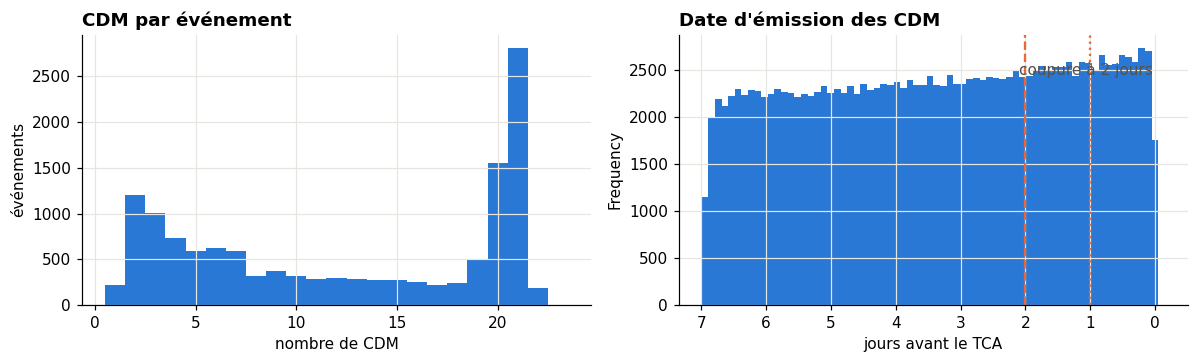

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
raw.groupby("event_id").size().plot.hist(bins=np.arange(0.5, 24.5), ax=axes[0], color=COLORS[0])
axes[0].set_title("CDM par événement"); axes[0].set_xlabel("nombre de CDM"); axes[0].set_ylabel("événements")
raw.time_to_tca.plot.hist(bins=70, ax=axes[1], color=COLORS[0])
axes[1].axvline(2, color=COLORS[1], ls="--"); axes[1].axvline(1, color=COLORS[1], ls=":")
axes[1].set_title("Date d'émission des CDM"); axes[1].set_xlabel("jours avant le TCA")
axes[1].text(2.1, axes[1].get_ylim()[1]*0.85, "coupure à 2 jours", color="#52514e")
axes[1].invert_xaxis(); plt.tight_layout()

Environ 13 CDM par événement, émis sur les 7 derniers jours. Le problème officiel ne donne que les CDM émis **au moins 2 jours avant** le TCA (le moment où il faut décider de manœuvrer) et demande le risque du **dernier** CDM (moins d'un jour avant).

## 2. L'entonnoir de construction du problème

Le jeu de test a été construit avec trois règles (au moins 2 CDM, dernier CDM à moins d'un jour, premier CDM à au moins 2 jours). Appliquer les mêmes règles au train est indispensable pour comparer ce qui est comparable.

In [3]:
elig = eligibility(raw)
y_all = raw.groupby("event_id").risk.last()
funnel = pd.DataFrame({
    "événements": [len(elig), int(elig.eligible.sum()), len(test)],
    "haut risque (r ≥ −6)": [int((y_all >= -6).sum()), int((y_all[elig.eligible] >= -6).sum()), int(test.is_high.sum())],
}, index=["train brut", "train éligible", "test officiel"])
funnel["part haut risque"] = (funnel.iloc[:, 1] / funnel.iloc[:, 0]).map("{:.2%}".format)
funnel

,événements,haut risque (r ≥ −6),part haut risque
train brut,13154,365,2.77%
train éligible,8293,66,0.80%
test officiel,2167,150,6.92%


**Premier piège majeur** : le test contient **9 fois plus** d'événements à haut risque (6,9 %) que le train éligible (0,8 %). Les organisateurs ont volontairement mis la plupart des cas intéressants dans le test. Conséquence : un modèle calibré sur le train sous-estimera les hauts risques sur le test, et toute règle qui « pousse vers le haut » les cas limites y sera récompensée (c'est ce qu'a exploité l'équipe gagnante).

## 3. Distribution du risque final

0.825 des événements du train finissent à −30


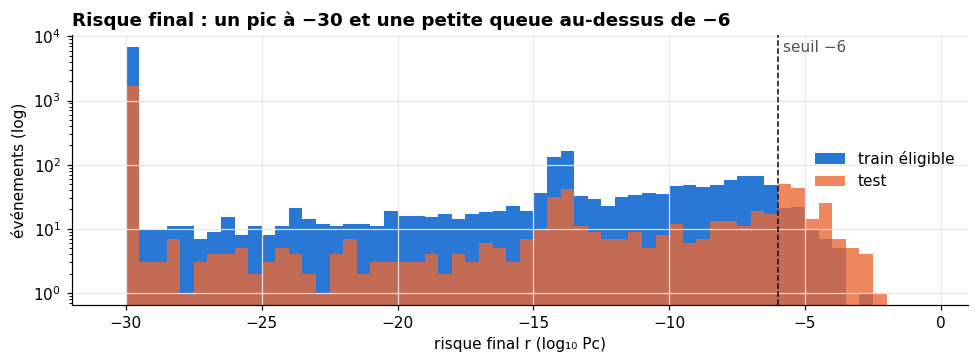

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(train.y, bins=np.arange(-30.5, 0, 0.5), color=COLORS[0], label="train éligible")
ax.hist(test.y, bins=np.arange(-30.5, 0, 0.5), color=COLORS[1], alpha=0.8, label="test")
ax.axvline(HIGH_RISK, color="#0b0b0b", ls="--", lw=1); ax.text(-5.8, ax.get_ylim()[1]*0.8, "seuil −6", color="#52514e")
ax.set_yscale("log"); ax.set_xlabel("risque final r (log₁₀ Pc)"); ax.set_ylabel("événements (log)")
ax.set_title("Risque final : un pic à −30 et une petite queue au-dessus de −6"); ax.legend(); plt.tight_layout()
print((train.y <= -30).mean().round(3), "des événements du train finissent à −30")

La majorité des événements finissent « sans risque » (−30) : quand les incertitudes diminuent en approchant du TCA, la plupart des rapprochements se révèlent sans danger. Seule la queue r ≥ −6 compte pour la métrique.

## 4. À quoi ressemblent les trajectoires de risque

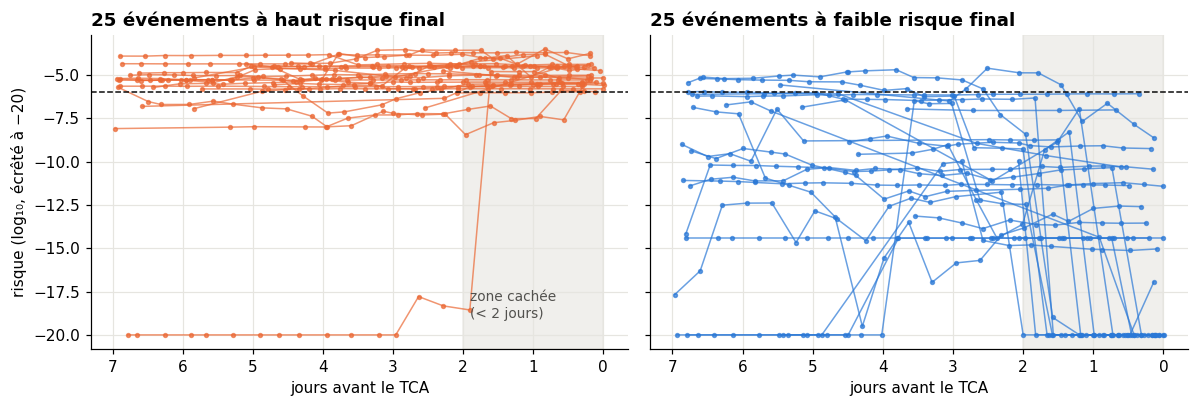

In [5]:
rng = np.random.default_rng(0)
full = raw[raw.event_id.isin(train.event_ids)]
hi = rng.choice(train.event_ids[train.is_high], 25, replace=False)
lo = rng.choice(train.event_ids[(~train.is_high) & (train.latest_risk > -15)], 25, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, ids, title, c in [(axes[0], hi, "25 événements à haut risque final", COLORS[1]),
                          (axes[1], lo, "25 événements à faible risque final", COLORS[0])]:
    for e in ids:
        d = full[full.event_id == e]
        ax.plot(d.time_to_tca, d.risk.clip(lower=-20), "-o", ms=2.5, lw=1, color=c, alpha=0.7)
    ax.axvspan(0, 2, color="#e6e5e0", alpha=0.6); ax.axhline(-6, color="#0b0b0b", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("jours avant le TCA"); ax.invert_xaxis()
axes[0].set_ylabel("risque (log₁₀, écrêté à −20)")
axes[0].text(1.9, -19, "zone cachée\n(< 2 jours)", color="#52514e", fontsize=9); plt.tight_layout()

Les risques évoluent souvent par paliers, et beaucoup convergent vers une valeur stable bien avant le TCA. C'est l'intuition derrière la baseline naïve. La zone grise (les 2 derniers jours) est invisible au moment de prédire.

## 5. Le cœur du problème : r₋₂ contre r

,train éligible,test
bas → bas,7966,1954
bas → HAUT (manqué par LRP),19,35
haut → bas (fausse alerte LRP),261,63
haut → haut,47,115


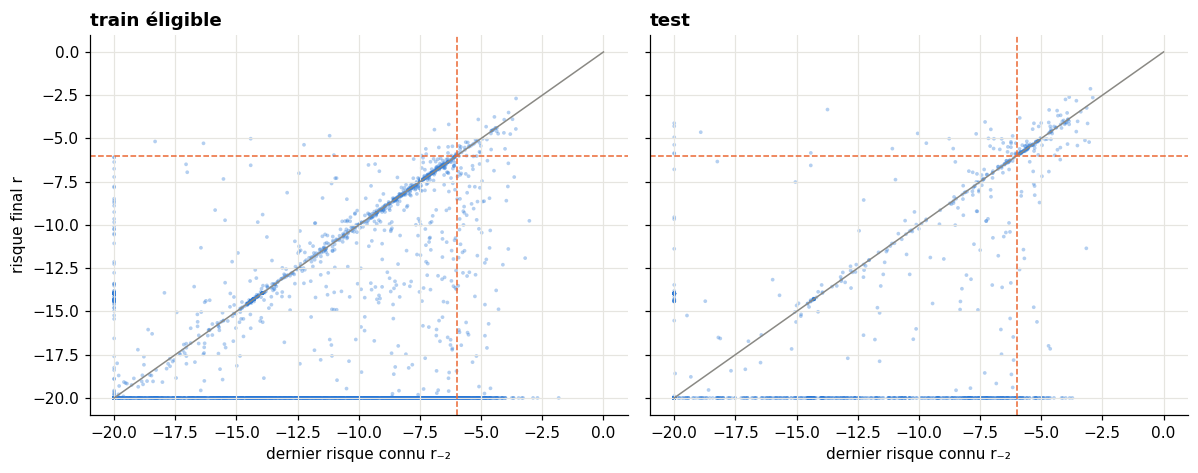

In [6]:
def quadrants(ds):
    r2, r = ds.latest_risk.to_numpy(), ds.y.to_numpy()
    return pd.Series({"bas → bas": ((r2 < -6) & (r < -6)).sum(), "bas → HAUT (manqué par LRP)": ((r2 < -6) & (r >= -6)).sum(),
                      "haut → bas (fausse alerte LRP)": ((r2 >= -6) & (r < -6)).sum(), "haut → haut": ((r2 >= -6) & (r >= -6)).sum()})
display(pd.DataFrame({"train éligible": quadrants(train), "test": quadrants(test)}))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, ds, t in [(axes[0], train, "train éligible"), (axes[1], test, "test")]:
    r2, r = ds.latest_risk.clip(lower=-20), ds.y.clip(lower=-20)
    ax.scatter(r2, r, s=6, alpha=0.35, color=COLORS[0], edgecolor="none")
    ax.plot([-20, 0], [-20, 0], color="#8a8984", lw=1)
    ax.axhline(-6, color=COLORS[1], ls="--", lw=1); ax.axvline(-6, color=COLORS[1], ls="--", lw=1)
    ax.set_xlabel("dernier risque connu r₋₂"); ax.set_title(t)
axes[0].set_ylabel("risque final r"); plt.tight_layout()

La diagonale domine : le dernier risque connu est un excellent prédicteur. Les erreurs de la baseline sont les deux quadrants hors diagonale :
- **bas → HAUT** : les faux négatifs, très pénalisés par F2 (recall pondéré 4 fois plus que la précision) ;
- **haut → bas** : les fausses alertes, peu pénalisées.

Au-dessus de la diagonale, les points sont rares : **le risque a tendance à baisser** en approchant du TCA.

## 6. De combien le risque bouge-t-il encore ?

In [7]:
d = train.y - train.latest_risk
bins = pd.cut(train.latest_risk, [-30.01, -20, -10, -8, -7, -6, -5, -4, 0])
stats = pd.DataFrame({
    "événements": d.groupby(bins, observed=True).size(),
    "reste à ±1": (d.abs() <= 1).groupby(bins, observed=True).mean(),
    "monte de plus de 1": (d > 1).groupby(bins, observed=True).mean(),
    "s'effondre (r ≤ −20)": (train.y <= -20).groupby(bins, observed=True).mean(),
    "Δ médian": d.groupby(bins, observed=True).median(),
})
stats.index.name = "r₋₂"
stats.style.format({"reste à ±1": "{:.0%}", "monte de plus de 1": "{:.0%}", "s'effondre (r ≤ −20)": "{:.0%}", "Δ médian": "{:.1f}"})

,événements,reste à ±1,monte de plus de 1,s'effondre (r ≤ −20),Δ médian
r₋₂,,,,,
"(-30.01, -20.0]",5313,87%,4%,97%,0.0
"(-20.0, -10.0]",1574,22%,3%,71%,-14.3
"(-10.0, -8.0]",464,28%,1%,61%,-20.3
"(-8.0, -7.0]",327,32%,2%,57%,-22.1
"(-7.0, -6.0]",307,31%,1%,53%,-18.0
"(-6.0, -5.0]",191,15%,1%,61%,-24.1
"(-5.0, -4.0]",96,17%,0%,60%,-25.1
"(-4.0, 0.0]",21,24%,0%,43%,-7.5


La distribution de Δ = r − r₋₂ est **bimodale** : soit le risque reste à peu près où il était, soit il **s'effondre vers −30** (l'incertitude diminue et le rapprochement se révèle sans danger). Pour les événements proches du seuil, environ la moitié s'effondrent ; seule une petite fraction monte. Un modèle de régression entraîné à minimiser une erreur quadratique va « moyenner » ces deux issues et prédire une forte baisse : il fera passer sous le seuil des événements qui finiront à haut risque. C'est exactement pourquoi le LightGBM naïf fait pire que la baseline (voir `results/leaderboard.md`), et un argument pour traiter d'abord le problème comme une **classification** (« restera-t-il au-dessus de −6 ? »).

## 7. Missions et types d'objets

In [8]:
def share(ds, col):
    last = ds.last
    return pd.DataFrame({"événements": last.groupby(col).size(),
                         "haut risque": ds.is_high.groupby(last[col]).sum()})
m = share(train, "mission_id").join(share(test, "mission_id"), lsuffix=" train", rsuffix=" test", how="outer").fillna(0).astype(int)
m.sort_values("événements train", ascending=False).head(12)

,événements train,haut risque train,événements test,haut risque test
mission_id,,,,
1,1333,10,333,32
15,1292,11,347,20
5,1274,6,348,19
7,1169,1,282,5
2,1153,13,316,29
6,558,3,136,6
19,495,1,131,9
3,331,9,96,7
9,245,0,59,3


In [9]:
o = share(train, "c_object_type").join(share(test, "c_object_type"), lsuffix=" train", rsuffix=" test", how="outer").fillna(0).astype(int)
o["taux haut risque train"] = (o["haut risque train"] / o["événements train"]).map("{:.2%}".format)
o

,événements train,haut risque train,événements test,haut risque test,taux haut risque train
c_object_type,,,,,
DEBRIS,4798,40,1280,83,0.83%
PAYLOAD,1007,0,242,2,0.00%
ROCKET BODY,100,0,29,1,0.00%
TBA,6,0,2,0,0.00%
UNKNOWN,2382,26,614,64,1.09%


Chaque `mission_id` est un satellite différent, sur une orbite différente : les distributions des variables en dépendent fortement. La répartition des hauts risques par mission diffère entre train et test (l'article le reconnaît : le découpage n'a pas été stratifié par mission). Les chasseurs de type `PAYLOAD` (satellites actifs, bien suivis) produisent rarement des hauts risques : c'est une des règles de l'équipe gagnante.

## 8. Qu'est-ce qui distingue les surprises ?

Parmi les événements proches du seuil (−8 ≤ r₋₂ < −6), comparons ceux qui restent bas et ceux qui finissent haut. L'article suggère que les surprises viennent d'**incertitudes plus grandes**.

In [10]:
both = pd.concat([train.last.assign(y=train.y, split="train"), test.last.assign(y=test.y, split="test")])
border = both[(both.risk >= -8) & (both.risk < -6)].copy()
border["issue"] = np.where(border.y >= -6, "finit HAUT", "reste bas")
cols = ["miss_distance", "mahalanobis_distance", "c_sigma_t", "c_sigma_r", "t_sigma_rdot", "c_obs_used",
        "c_time_lastob_start", "time_to_tca", "max_risk_estimate"]
summary = border.groupby("issue")[cols].median().T.round(3)
summary["n"] = ""; summary.loc[cols[0], "n"] = str(border.issue.value_counts().to_dict())
summary

issue,finit HAUT,reste bas,n
miss_distance,3523.000,7222.000,"{'reste bas': 810, 'finit HAUT': 34}"
mahalanobis_distance,14.378,31.390,
c_sigma_t,6310.637,10844.028,
c_sigma_r,229.847,202.618,
t_sigma_rdot,0.045,0.048,
c_obs_used,20.500,21.000,
c_time_lastob_start,1.000,2.000,
time_to_tca,2.205,2.213,
max_risk_estimate,-5.772,-6.088,


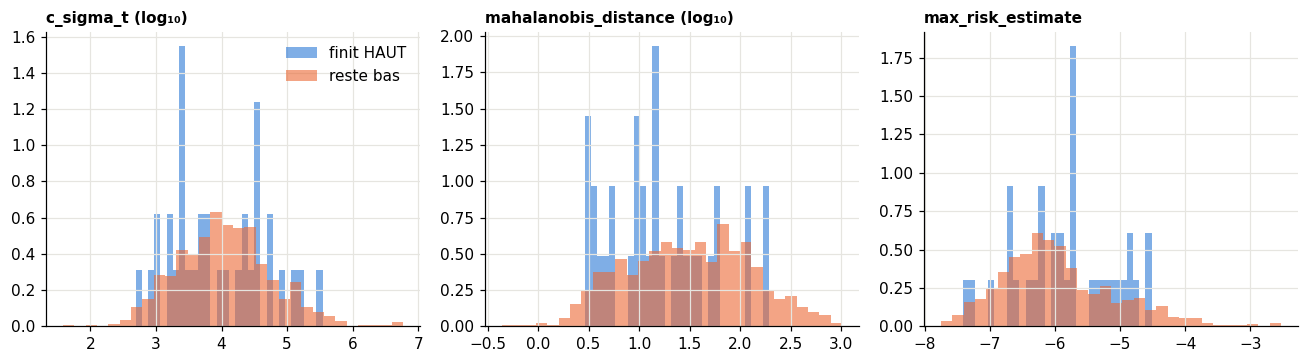

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, c in zip(axes, ["c_sigma_t", "mahalanobis_distance", "max_risk_estimate"]):
    for k, (lab, g) in enumerate(border.groupby("issue")):
        v = np.log10(g[c].clip(lower=1e-3)) if c != "max_risk_estimate" else g[c]
        ax.hist(v, bins=30, alpha=0.6, density=True, color=COLORS[k], label=lab)
    ax.set_title(c + (" (log₁₀)" if c != "max_risk_estimate" else ""), fontsize=10)
axes[0].legend(); plt.tight_layout()

Parmi les cas limites, ceux qui finissent à haut risque (34, contre 810 qui restent bas) ont une **distance de passage plus petite** (médiane 3,5 km contre 7,2 km), une **distance de Mahalanobis deux fois plus faible** et un `max_risk_estimate` plus élevé ; leur incertitude sur la position du chasseur n'est pas plus grande, plutôt plus petite. Lecture physique : le passage est déjà proche, et quand l'incertitude se resserre, la probabilité de collision monte au lieu de s'effondrer. Ce sont des variables à donner en priorité à un classifieur. Avec quelques dizaines d'exemples, il faudra rester prudent (régularisation, validation répétée).

## 9. Valeurs manquantes

In [12]:
na = pd.concat([train.cdms.isna().mean(), test.cdms.isna().mean()], axis=1, keys=["train", "test"])
na[na.max(axis=1) > 0].sort_values("train", ascending=False).round(3).head(15)

,train,test
c_rcs_estimate,0.306,0.305
c_crdot_r,0.044,0.050
c_sigma_ndot,0.044,0.050
c_cndot_r,0.044,0.050
c_ctdot_rdot,0.044,0.050
c_ctdot_n,0.044,0.050
c_ctdot_t,0.044,0.050
c_ctdot_r,0.044,0.050
c_crdot_n,0.044,0.050
c_crdot_t,0.044,0.050


`c_rcs_estimate` (taille radar du chasseur) manque dans un tiers des CDM ; certaines corrélations de covariance du chasseur manquent dans 5 % des cas. LightGBM gère les valeurs manquantes nativement ; un réseau de neurones demandera une imputation et un indicateur de manque.

## 10. Ce qu'il faut retenir

1. **Le dernier risque connu est le meilleur prédicteur**, et de loin. Tout modèle doit être formulé comme une *correction* de cette baseline, et comparé à elle sur les mêmes plis.
2. **Le problème est surtout un problème de classification autour du seuil −6** : le MSE ne porte que sur les vrais hauts risques, et F2 punit surtout les faux négatifs. Il est souvent plus malin de séparer « dépassera-t-il −6 ? » (classifieur, seuil choisi pour F2) et « de combien ? ».
3. **Très peu d'exemples positifs** : 66 hauts risques dans le train éligible, dont seulement 19 « surprises » (bas → haut). Le bruit de validation est énorme ; l'intervalle de confiance bootstrap du score LRP sur le test va de 0,46 à 0,97.
4. **Le test ne ressemble pas au train** (9 fois plus de hauts risques, missions différentes). Ce qui marche sur le test peut perdre en validation croisée, et inversement : c'est le cas des règles de l'équipe gagnante.
5. Les variables qui distinguent les surprises parmi les cas limites sont la distance de passage, la distance de Mahalanobis et `max_risk_estimate`.
6. Pistes pour la suite : utiliser aussi les événements non éligibles du train pour apprendre la dynamique du risque, prédire une **probabilité de dépasser −6** plutôt qu'une valeur, et une distribution plutôt qu'un point.